# Heuristic method: greedy + SA

runs `src/model_heuristic.py` on 3 CVRPLIB instances, then shows the SA convergence and a route map. code is all in `src/`, this just calls it.

- greedy: nearest customer that fits, else new truck
- SA: random relocate / swap / 2-opt, worse move accepted with prob exp(-delta/T), T = alpha * T

In [1]:
import sys
sys.path.insert(0, "../src")

import common
import loader
import model_heuristic
import plots

## Run SA on three instances

In [2]:
for name in ["P-n16-k8", "E-n22-k4", "A-n32-k5"]:
    inst = loader.load_cvrplib(f"../data/instances/{name}.vrp")
    greedy_cost = common.solution_cost(inst, model_heuristic.greedy(inst))
    sol = model_heuristic.solve(inst, seed=0)
    print(f"{name}: greedy {greedy_cost:.0f} -> SA {sol.cost:.0f} "
          f"(optimum {inst.optimum}, gap {sol.gap_to(inst.optimum):.2f}%, {sol.runtime:.1f}s)")

P-n16-k8: greedy 497 -> SA 450 (optimum 450, gap 0.00%, 0.4s)


E-n22-k4: greedy 464 -> SA 375 (optimum 375, gap 0.00%, 0.9s)


A-n32-k5: greedy 1145 -> SA 828 (optimum 784, gap 5.61%, 1.9s)


Full solution for the last instance:

In [3]:
print(common.describe(inst, sol))

A-n32-k5  method=sa  status=feasible
  cost=828  optimum=784  gap=5.61%
  runtime=1.91s  feasible=True (ok)
  route 0: 0 -> 27 -> 29 -> 15 -> 10 -> 25 -> 5 -> 20 -> 0  (load 91/100, dist 195)
  route 1: 0 -> 22 -> 9 -> 11 -> 4 -> 28 -> 8 -> 18 -> 24 -> 0  (load 99/100, dist 238)
  route 2: 0 -> 14 -> 6 -> 23 -> 3 -> 2 -> 1 -> 12 -> 0  (load 90/100, dist 189)
  route 3: 0 -> 21 -> 31 -> 19 -> 17 -> 13 -> 7 -> 26 -> 0  (load 98/100, dist 155)
  route 4: 0 -> 30 -> 16 -> 0  (load 32/100, dist 51)


## Convergence and route map (A-n32-k5, seed 0)

saved results/figures/sa_convergence.png
saved results/figures/routes_A-n32-k5_sa.png


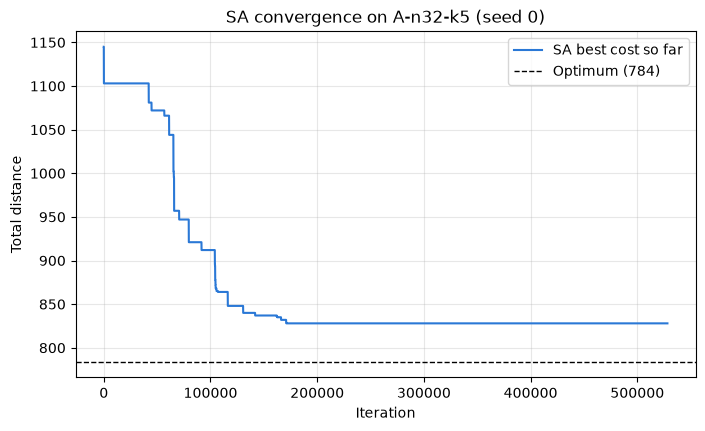

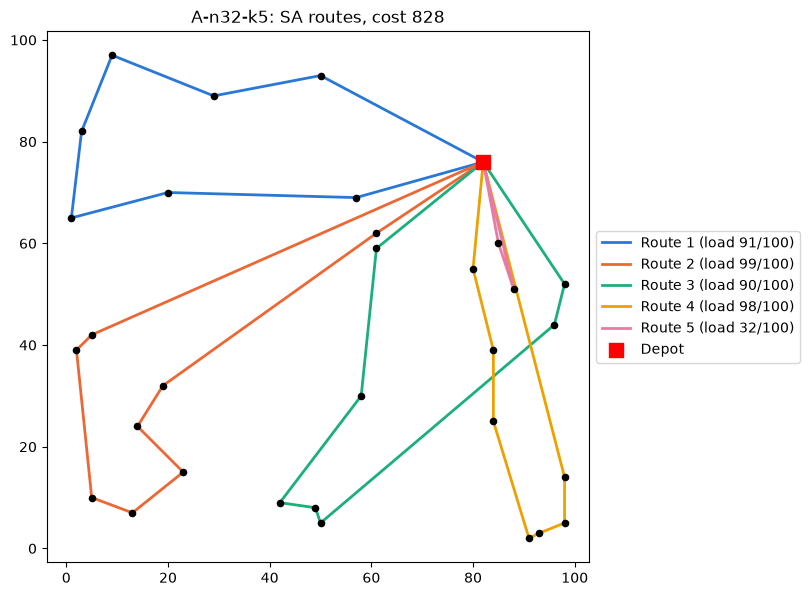

In [4]:
plots.sa_convergence(inst, sol)
plots.plot_routes(inst, sol);